# Finite differences and the 1D diffusion equation

Solve $\partial u/\partial t = \alpha\,\partial^2 u/\partial x^2$ on $0 \le x \le 1$ with $u = 0$ at both ends and $u(x, 0) = \sin(\pi x)$.

The exact solution is $u(x,t) = \sin(\pi x)\,e^{-\alpha \pi^2 t}$.

The explicit (FTCS) scheme is stable only when $r = \alpha\,\Delta t/\Delta x^2 \le 1/2$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (7, 4)

In [2]:
alpha, nx, t_end = 0.01, 51, 5.0
x = np.linspace(0, 1, nx)
dx = x[1] - x[0]

def exact(x, t):
    return np.sin(np.pi * x) * np.exp(-alpha * np.pi**2 * t)

**Exercise 1.** Write one explicit time step:
$u_i^{n+1} = u_i^n + r\,(u_{i+1}^n - 2u_i^n + u_{i-1}^n)$. Keep the boundary values at zero.

In [3]:
def ftcs_step(u, r):
    un = u.copy()
    un[1:-1] = u[1:-1] + r * (u[2:] - 2 * u[1:-1] + u[:-2])
    return un


def solve_explicit(r):
    dt = r * dx**2 / alpha
    u = np.sin(np.pi * x)
    for _ in range(int(round(t_end / dt))):
        u = ftcs_step(u, r)
    return u

for r in (0.25, 0.5, 0.6):
    u = solve_explicit(r)
    print(f"r = {r:4}: max error = {np.abs(u - exact(x, t_end)).max():.2e}")

r = 0.25: max error = 4.96e-05
r =  0.5: max error = 1.98e-04
r =  0.6: max error = 2.45e+13


At $r = 0.6$ the error explodes. Round-off errors in the shortest wavelength are multiplied by $|1 - 4r| = 1.4$ every step.

**Exercise 2.** Write an implicit (backward Euler) step. It is stable for any $r$. You need to solve $A\,u^{n+1} = u^n$ with $A$ tridiagonal: $1 + 2r$ on the diagonal and $-r$ next to it. Use `np.linalg.solve`.

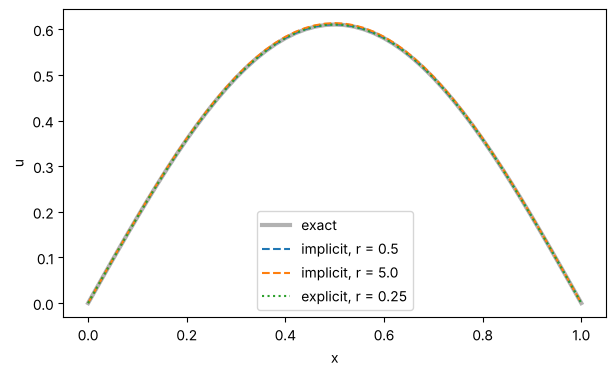

In [4]:
def implicit_matrix(n, r):
    A = np.eye(n) * (1 + 2 * r) - r * np.eye(n, k=1) - r * np.eye(n, k=-1)
    A[0, :] = 0; A[0, 0] = 1        # boundary rows keep u = 0
    A[-1, :] = 0; A[-1, -1] = 1
    return A


def solve_implicit(r):
    dt = r * dx**2 / alpha
    A = implicit_matrix(nx, r)
    u = np.sin(np.pi * x)
    for _ in range(int(round(t_end / dt))):
        u = np.linalg.solve(A, u)
    return u

fig, ax = plt.subplots()
ax.plot(x, exact(x, t_end), "k", lw=3, alpha=0.3, label="exact")
for r in (0.5, 5.0):
    ax.plot(x, solve_implicit(r), "--", label=f"implicit, r = {r}")
ax.plot(x, solve_explicit(0.25), ":", label="explicit, r = 0.25")
ax.set_xlabel("x"); ax.set_ylabel("u"); ax.legend();

**Question.** The implicit scheme is stable at $r = 5$. Is it also accurate there? Compare the error with $r = 0.5$, and note why in the lesson file.